# Exploring the training data

Before training the model, let's explore the training data. Dates, labels, class balance, clouds, value ranges and radar signals from the training data are checked. This notebook only uses seg_train, seg_val and holdout events are not opened. A later section (section 10) compares the Nepal case study with the training data.


In [1]:
import glob, io, json, tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import zarr
from numcodecs import Blosc

SHARDS = "D:/data/shards"
RAW = "D:/data/impactmesh_flood_all"
codec = Blosc()

## Reading the shards

A shard is a single .tar file which holds about 125 patches. Training data is packed this way so that its compact and faster to read. Each patch is stored as five files in a tar: S2-optical, S1- radar, DEM - elevation, mask (compressed numpy arrays/labels) and a meta.json.
Each patch is 256x256 pixels at 10m. Array shapes (time, bands, height, width): S2 (2,12,256,256) with VV and VH. VV and VH are the two polarisations - VV being received vertical and VH being received horizontal. S1 radar only has 2 polisations so 2 bands and S2 has 12 spectral bands each measuring a different color of light.
S1 (2, 2, 256, 256) also with VV and VH, DEM (1, 256, 256), mask (256, 256).
Time 0 is pre-flood, time 1 is the during the flood.

In [2]:
def read_shard(path, images=True):
    """Yield one dict per patch. images=False only reads mask + meta (much faster)."""
    with tarfile.open(path) as tar:
        sample, key = {}, None
        for member in tar:
            k, ext = member.name.split(".", 1)
            if key is not None and k != key:
                yield sample
                sample = {}
            key = k
            if ext == "meta.json":
                sample["meta"] = json.load(tar.extractfile(member))
            elif ext == "mask.npy.blosc" or images:
                data = codec.decode(tar.extractfile(member).read())
                sample[ext.split(".")[0]] = np.load(io.BytesIO(data))
        if sample:
            yield sample


S2_BANDS = ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B09", "B11", "B12"]
S1_BANDS = ["VV", "VH"]
CLASSES = {-1: "ignore", 0: "no water", 1: "permanent water", 2: "flood"}

## 1. One row per patch (mask + metadata)

First, a table with one row per patch is built with its events and split showing the count of each class

In [3]:
rows = []
for split in ["seg_train", "seg_val"]:
    for path in sorted(glob.glob(f"{SHARDS}/{split}/shard-*.tar")):
        for s in read_shard(path, images=False):
            m, meta = s["mask"], s["meta"]
            rows.append({
                "patch_id": meta["patch_id"], "event": meta["event"], "split": split,
                "ignore": (m == -1).mean(), "no_water": (m == 0).mean(),
                "permanent": (m == 1).mean(), "flood": (m == 2).mean(),
                "s1_pre": meta["s1_timestamps"][0], "s1_event": meta["s1_timestamps"][1],
                "s2_pre": meta["s2_timestamps"][0], "s2_event": meta["s2_timestamps"][1],
                "s2_pre_ok": meta["s2_data_mask"][0], "s2_event_ok": meta["s2_data_mask"][1],
            })
patches = pd.DataFrame(rows)
print(len(patches), "patches,", patches.event.nunique(), "events")
patches.groupby("split").agg(patches=("patch_id", "size"), events=("event", "nunique"))

16086 patches, 134 events


,patches,events
split,,
seg_train,15340,123
seg_val,746,11


Here, the number of patches and events in each split is shown. 16,086 patches come from 134 events (seg_train 15,340 / 123, seg_val 746 / 11), matching the split lists.

## 2. Are the dates in the right order?

The pre-event image should be taken before the Copernicus EMS activation date, and the event image
around or after it.

In [4]:
events = pd.read_csv("../splits/event_assignment.csv", parse_dates=["date"])
p = patches.merge(events[["event", "date"]], on="event")
for col in ["s1_pre", "s1_event", "s2_pre", "s2_event"]:
    t = pd.to_datetime(p[col], utc=True).dt.tz_localize(None)
    p[col + "_days"] = (t - p["date"]).dt.days
day_cols = ["s1_pre_days", "s1_event_days", "s2_pre_days", "s2_event_days"]
p[day_cols].describe().round(1)

,s1_pre_days,s1_event_days,s2_pre_days,s2_event_days
count,16086.0,16086.0,16086.0,16086.0
mean,-19.9,3.2,-20.2,3.6
std,8.8,5.4,9.2,5.6
min,-61.0,-13.0,-60.0,-12.0
25%,-26.0,1.0,-28.0,1.0
50%,-19.0,2.0,-19.0,3.0
75%,-13.0,4.0,-13.0,5.0
max,-3.0,266.0,-4.0,269.0


S1 pre-event image after activation: 0.0 % of patches
S1 event image before pre-event image: 0.0 %
S1 event image more than 7 days after activation: 14.1% of patches, 21 events
S1 event image more than 14 days after activation: 4.3% of patches, 7 events
S1 event image more than 30 days after activation: 0.0% of patches, 1 events


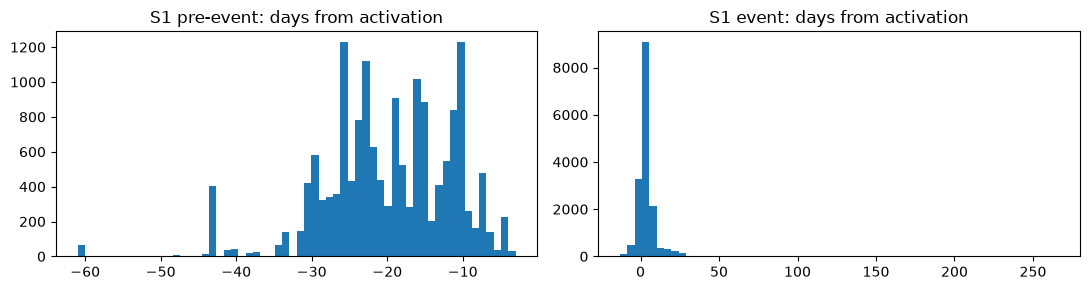

In [5]:
print("S1 pre-event image after activation:", round((p.s1_pre_days > 0).mean() * 100, 1), "% of patches")
print("S1 event image before pre-event image:", round((p.s1_event_days < p.s1_pre_days).mean() * 100, 1), "%")
for d in [7, 14, 30]:
    late = p.s1_event_days > d
    print(f"S1 event image more than {d} days after activation: {late.mean() * 100:.1f}% of patches, "
          f"{p[late].event.nunique()} events")

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].hist(p.s1_pre_days.dropna(), bins=60); ax[0].set_title("S1 pre-event: days from activation")
ax[1].hist(p.s1_event_days.dropna(), bins=60); ax[1].set_title("S1 event: days from activation")
plt.tight_layout()

Dates are in order for every patch. The pre flood image is taken before the activation (median 19 days before) and the flood image is taken a median of 2 days after. About 7 events of the patches have a flood images taken more than 14 days late. One event is over 30 days

## 3. Class balance

Every patch is 256 x 256, so the mean of the per-patch fractions is the pixel fraction.
We are using IBM's class weights `[0.044, 0.487, 0.469]` (no water, permanent, flood), computed on
their train split.

In [6]:
train = patches[patches.split == "seg_train"]
frac = train[["no_water", "permanent", "flood"]].mean()
inv = 1 / frac
balance = pd.DataFrame({
    "pixel fraction": frac,
    "inverse freq (normalised)": inv / inv.sum(),
    "IBM class weight": [0.044, 0.487, 0.469],
})
print("ignore pixels:", round(train.ignore.mean() * 100, 2), "%")
balance.round(3)

ignore pixels: 1.74 %


,pixel fraction,inverse freq (normalised),IBM class weight
no_water,0.819,0.048,0.044
permanent,0.083,0.469,0.487
flood,0.081,0.484,0.469


 About 82% of pixels are no water, 8% permanent water and 8% flood while 1.7% is ignored. Our normalised
inverse frequencies gives 0.048 / 0.469 / 0.484 are within 0.02 of IBM's weights, so keeping their
weights is fine.

,no_water,permanent,flood,patches
event,,,,
EMSR629,0.337,0.049,0.614,296
EMSR857,0.488,0.042,0.451,366
EMSR567,0.577,0.077,0.299,97
EMSR339,0.494,0.238,0.267,25
EMSR565,0.540,0.135,0.256,18
EMSR554,0.737,0.032,0.232,141
EMSR470,0.768,0.007,0.221,120
EMSR848,0.718,0.069,0.206,388
EMSR645,0.720,0.067,0.206,287


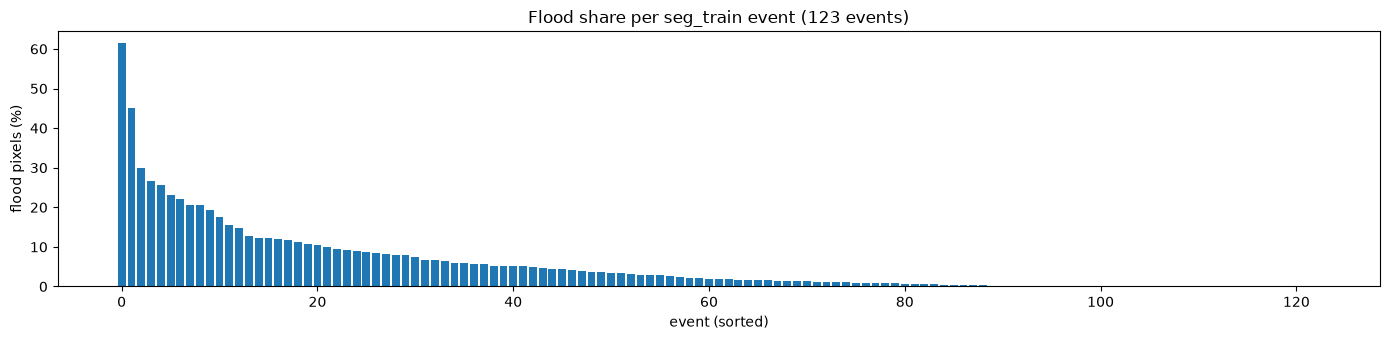

In [7]:
per_event = train.groupby("event")[["no_water", "permanent", "flood"]].mean()
per_event["patches"] = train.groupby("event").size()
per_event = per_event.sort_values("flood", ascending=False)

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.bar(range(len(per_event)), per_event.flood * 100)
ax.set_xlabel("event (sorted)"); ax.set_ylabel("flood pixels (%)")
ax.set_title(f"Flood share per seg_train event ({len(per_event)} events)")
plt.tight_layout()
per_event.head(10).round(3)

In [8]:
# how much of the flood pixels come from the biggest events
flood_px = train.groupby("event").flood.sum().sort_values(ascending=False)
share = flood_px.cumsum() / flood_px.sum()
print("events holding 50% of flood pixels:", (share < 0.5).sum() + 1)
print("events holding 90% of flood pixels:", (share < 0.9).sum() + 1)

events holding 50% of flood pixels: 7
events holding 90% of flood pixels: 32


Flood pixels are concentrated: 7 of 123 events hold half of them and 32 hold 90%.
Pooled pixel metrics would mostly reflect those few events.

## 4. How much of each patch is flooded

patches with flood > 0%: 63.0%
patches with flood > 1%: 42.8%
patches with flood > 10%: 19.9%
patches with flood > 50%: 4.9%


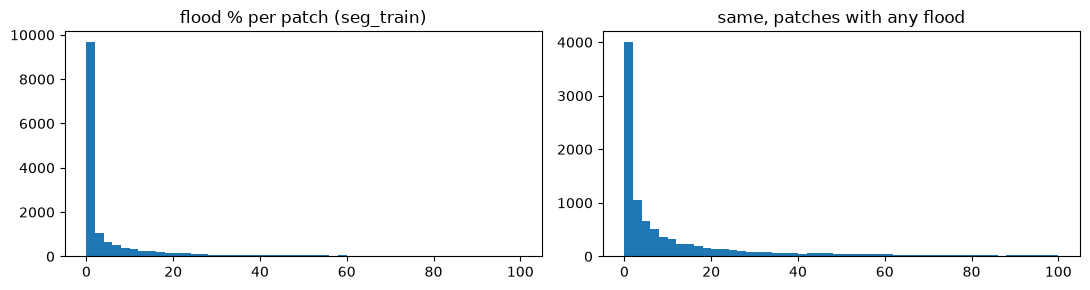

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].hist(train.flood * 100, bins=50); ax[0].set_title("flood % per patch (seg_train)")
ax[1].hist(train.flood[train.flood > 0] * 100, bins=50); ax[1].set_title("same, patches with any flood")
plt.tight_layout()

for t in [0, 0.01, 0.1, 0.5]:
    print(f"patches with flood > {t * 100:g}%: {(train.flood > t).mean() * 100:.1f}%")

37% of seg_train patches have no flood at all and only 20% are more than 10% flooded.
For the error spotter this means many patches have little to get wrong, so flood fraction is a
needed control.

## 5. Example patches

Patches from different events with at least 10% flood. S2 shown as true colour (B04, B03, B02),
S1 as VV in dB.

In [10]:
examples, seen = [], set()
for path in sorted(glob.glob(f"{SHARDS}/seg_train/shard-*.tar"))[:3]:
    for s in read_shard(path):
        ev = s["meta"]["event"]
        if ev not in seen and (s["mask"] == 2).mean() > 0.1:
            examples.append(s); seen.add(ev)
        if len(examples) == 5:
            break
    if len(examples) == 5:
        break
len(examples)

5

mask colours: grey = ignore, beige = no water, blue = permanent water, red = flood


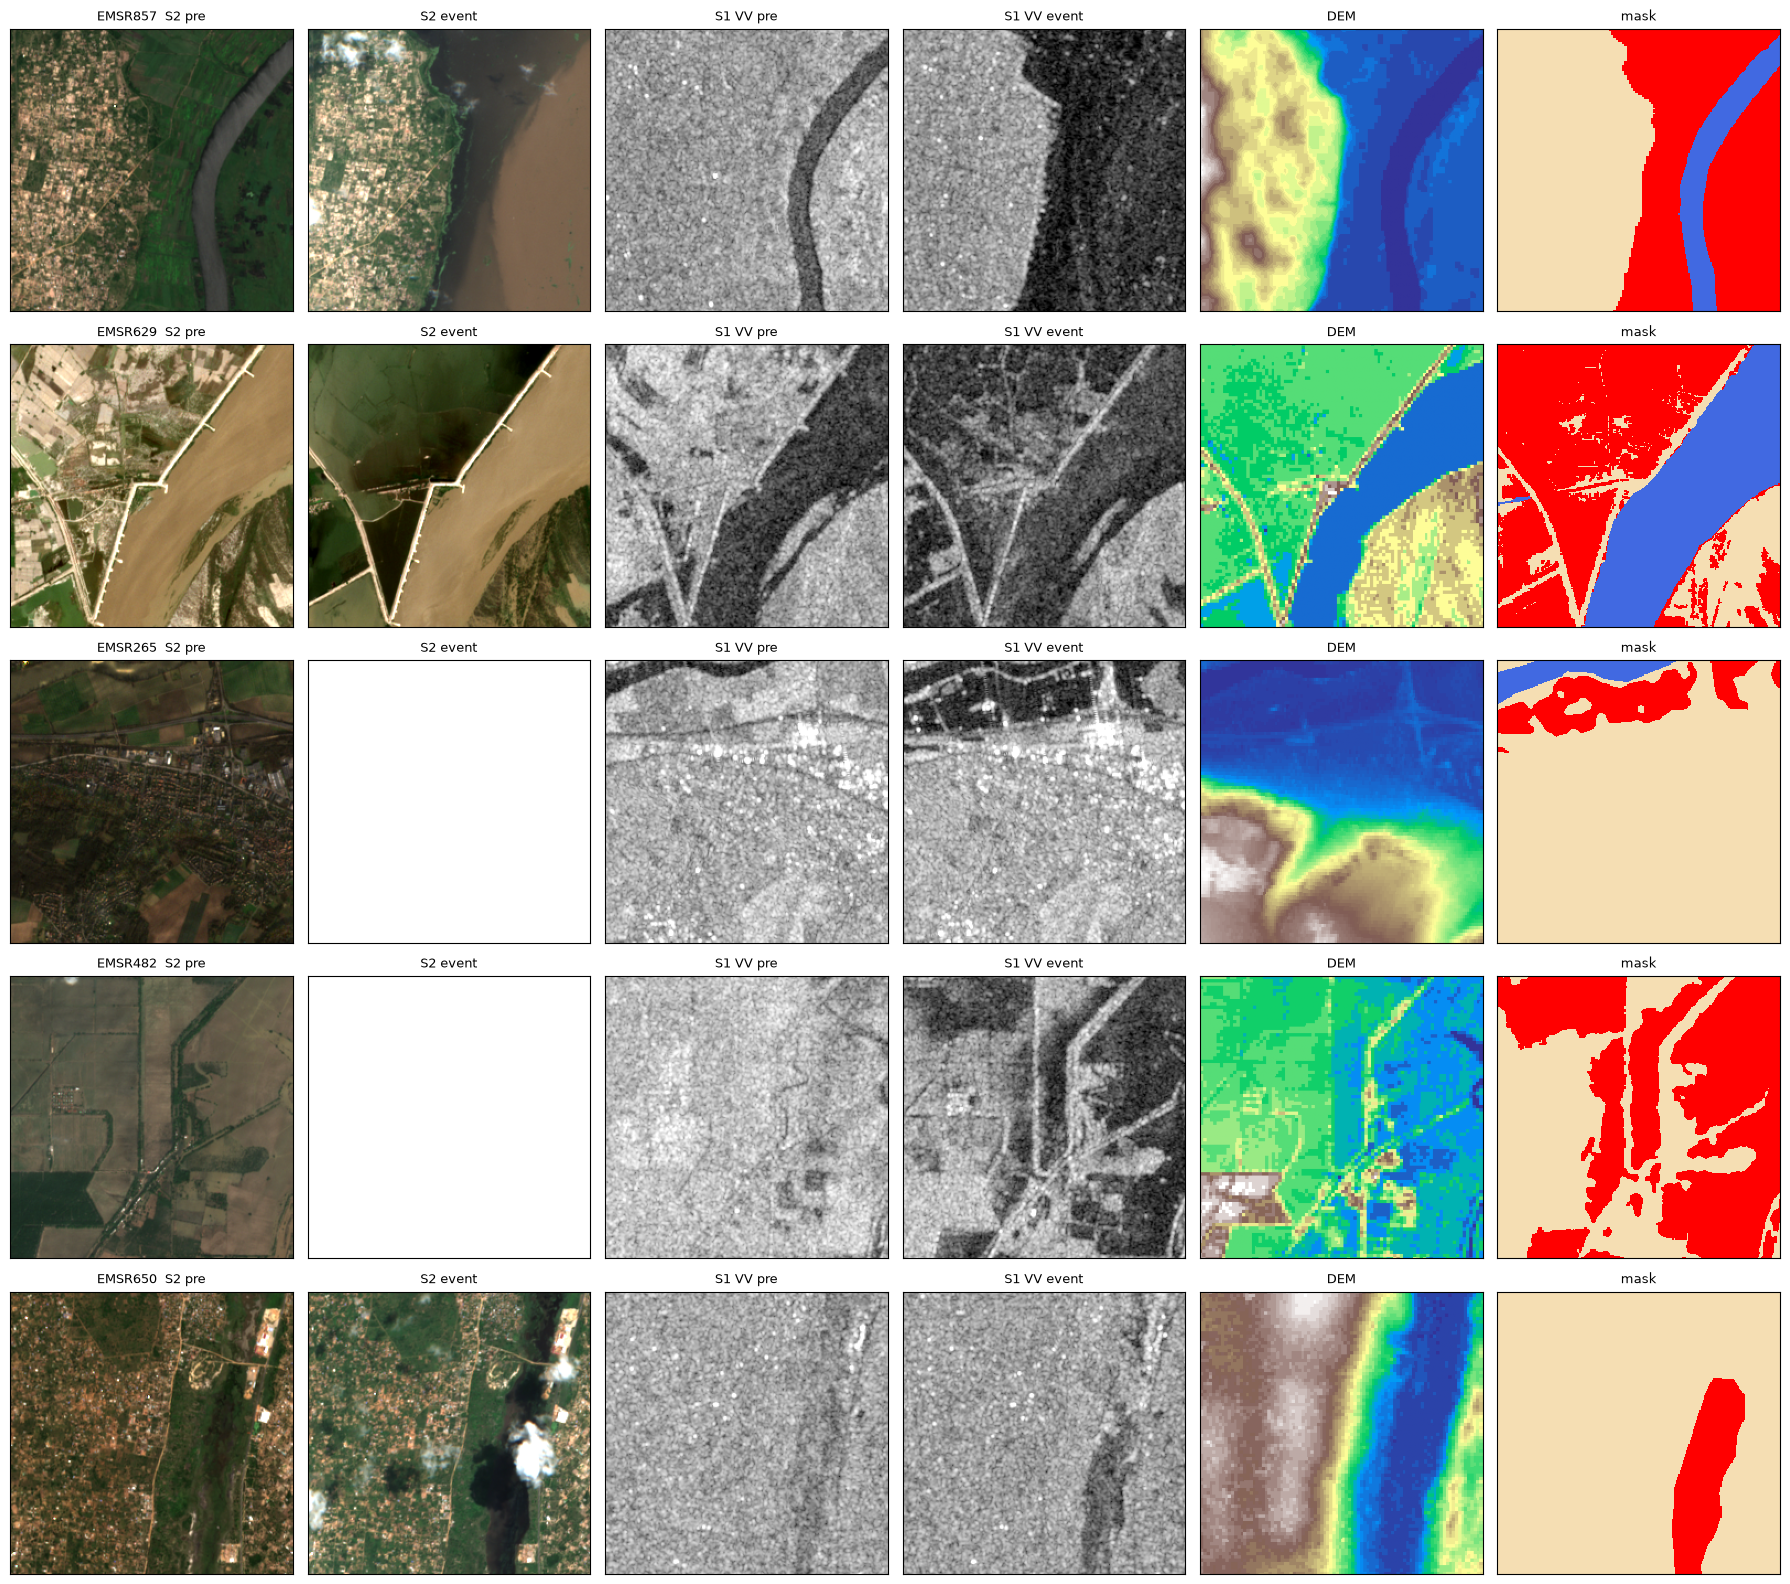

In [11]:
def rgb(s2, t):
    img = s2[t, [3, 2, 1]].transpose(1, 2, 0).astype(float)
    return np.clip(img / 3000, 0, 1)

mask_cmap = ListedColormap(["lightgrey", "wheat", "royalblue", "red"])   # -1, 0, 1, 2
titles = ["S2 pre", "S2 event", "S1 VV pre", "S1 VV event", "DEM", "mask"]

fig, axes = plt.subplots(len(examples), 6, figsize=(18, 3.2 * len(examples)))
for row, s in zip(axes, examples):
    s1 = s["s1rtc"].astype(float)
    imgs = [rgb(s["s2l2a"], 0), rgb(s["s2l2a"], 1), s1[0, 0], s1[1, 0], s["dem"][0], s["mask"]]
    for i, (ax, img) in enumerate(zip(row, imgs)):
        if i in (2, 3):
            ax.imshow(img, cmap="gray", vmin=-25, vmax=0)
        elif i == 5:
            ax.imshow(img, cmap=mask_cmap, vmin=-1.5, vmax=2.5, interpolation="nearest")
        else:
            ax.imshow(img, cmap="terrain" if i == 4 else None)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(titles[i] if i else f"{s['meta']['event']}  {titles[0]}", fontsize=9)
print("mask colours: grey = ignore, beige = no water, blue = permanent water, red = flood")
plt.tight_layout()

The masks line up with the images: the flood and river outlines match the water that we see in S2 and the dark areas seen in S1. Two of the five flood S2 images are completely cloud-covered, while the radar images at the same time still shows water.

## 6. Clouds in the S2 images

The shards don't keep the cloud mask, so this reads it from the unpacked S2 files for a random
2,000 seg_train patches. Cloud = medium or high probability cloud in the scene classification;
thin cirrus is counted separately.

In [12]:
rng = np.random.default_rng(0)
sample_ids = rng.choice(train.patch_id.values, 2000, replace=False)

cloud_rows = []
for pid in sample_ids:
    store = zarr.storage.ZipStore(f"{RAW}/S2L2A/{pid}_S2L2A.zarr.zip", mode="r")
    cm = zarr.open_consolidated(store, mode="r")["cloud_mask"].get_orthogonal_selection(([1, 2], slice(None), slice(None)))
    store.close()
    cloud_rows.append({"patch_id": pid,
                       "cloud_pre": (cm[0] == 1).mean(), "cloud_event": (cm[1] == 1).mean(),
                       "cirrus_pre": (cm[0] == 2).mean(), "cirrus_event": (cm[1] == 2).mean(),
                       "nodata_event": (cm[1] == -1).mean()})
clouds = pd.DataFrame(cloud_rows).merge(train[["patch_id", "event", "flood"]], on="patch_id")
clouds.describe().round(3)

,cloud_pre,cloud_event,cirrus_pre,cirrus_event,nodata_event,flood
count,2000.000,2000.000,2000.000,2000.000,2000.0,2000.000
mean,0.090,0.481,0.049,0.039,0.0,0.082
std,0.201,0.453,0.173,0.150,0.0,0.178
min,0.000,0.000,0.000,0.000,0.0,0.000
25%,0.000,0.002,0.000,0.000,0.0,0.000
50%,0.000,0.360,0.000,0.000,0.0,0.004
75%,0.065,1.000,0.000,0.000,0.0,0.065
max,1.000,1.000,1.000,1.000,0.0,1.000


cloud > 10%:  pre  21.3%   event  59.4% of patches
cloud > 50%:  pre   5.9%   event  47.0% of patches
cloud > 90%:  pre   1.8%   event  38.6% of patches

patches with >1% flood (861): event image >50% cloud in 48.4%


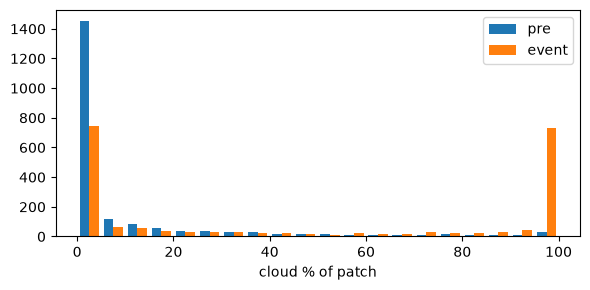

In [13]:
for t in [0.1, 0.5, 0.9]:
    print(f"cloud > {t * 100:.0f}%:  pre {(clouds.cloud_pre > t).mean() * 100:5.1f}%   "
          f"event {(clouds.cloud_event > t).mean() * 100:5.1f}% of patches")

flooded = clouds[clouds.flood > 0.01]
print(f"\npatches with >1% flood ({len(flooded)}): event image >50% cloud in "
      f"{(flooded.cloud_event > 0.5).mean() * 100:.1f}%")

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist([clouds.cloud_pre * 100, clouds.cloud_event * 100], bins=20, label=["pre", "event"])
ax.set_xlabel("cloud % of patch"); ax.legend(); plt.tight_layout()

Flood-time optical images are often unusable: 47% of patches are more than half cloud at
flood time (6% before the event), and 39% are almost fully cloudy. Patches with flood are just as cloudy. Flood is usually present alongside storms which is the situation emergency responder also face.This is an argument for training a radar + DEM model first.

## 7. Value ranges vs. the normalisation stats

Before the data goes into the model, each band is rescaled so that all bands sit on a similar scale around 0. The model uses IBM's per-band means and stds (computed on their train split). The values come from about 380 seg_train patches which mix many floods because they were shuffled using both time steps while leaving out missing pixels.

In [14]:
IBM_MEAN = {"S2L2A": [1460.264, 1499.629, 1663.836, 1651.188, 2056.615, 2747.754, 2990.725,
                      3074.264, 3130.254, 3578.565, 2111.968, 1501.892],
            "S1RTC": [-9.871, -15.993], "DEM": [154.914]}
IBM_STD = {"S2L2A": [2587.746, 2477.497, 2315.289, 2303.498, 2283.186, 2087.282, 2048.065,
                     2099.017, 2008.163, 3010.72, 1332.457, 1162.548],
           "S1RTC": [4.028, 3.899], "DEM": [368.796]}

vals = {"S2L2A": [], "S1RTC": [], "DEM": []}
for path in sorted(glob.glob(f"{SHARDS}/seg_train/shard-*.tar"))[:3]:
    for s in read_shard(path):
        s2 = s["s2l2a"].astype(np.float32); s2[s2 == -9999] = np.nan
        vals["S2L2A"].append(s2.transpose(1, 0, 2, 3).reshape(12, -1)[:, ::16])
        vals["S1RTC"].append(s["s1rtc"].astype(np.float32).transpose(1, 0, 2, 3).reshape(2, -1)[:, ::16])
        vals["DEM"].append(s["dem"].astype(np.float32).reshape(1, -1)[:, ::16])

rows = []
for mod, names in [("S2L2A", S2_BANDS), ("S1RTC", S1_BANDS), ("DEM", ["DEM"])]:
    v = np.concatenate(vals[mod], axis=1)
    for i, name in enumerate(names):
        rows.append({"band": f"{mod} {name}", "our mean": np.nanmean(v[i]), "IBM mean": IBM_MEAN[mod][i],
                     "our std": np.nanstd(v[i]), "IBM std": IBM_STD[mod][i]})
norm = pd.DataFrame(rows).set_index("band")
norm["mean diff (in IBM stds)"] = (norm["our mean"] - norm["IBM mean"]) / norm["IBM std"]
norm.round(2)

,our mean,IBM mean,our std,IBM std,mean diff (in IBM stds)
band,,,,,
S2L2A B01,2470.550049,1460.26,3464.629883,2587.75,0.39
S2L2A B02,2444.199951,1499.63,3306.820068,2477.50,0.38
S2L2A B03,2529.370117,1663.84,3092.669922,2315.29,0.37
S2L2A B04,2476.139893,1651.19,3061.760010,2303.50,0.36
S2L2A B05,2850.989990,2056.61,3039.600098,2283.19,0.35
S2L2A B06,3398.600098,2747.75,2738.889893,2087.28,0.31
S2L2A B07,3582.030029,2990.72,2649.739990,2048.06,0.29
S2L2A B08,3672.290039,3074.26,2724.219971,2099.02,0.28
S2L2A B8A,3671.290039,3130.25,2571.560059,2008.16,0.27


Radar and elevation match IBMS value closely. S2 is brighter around 0.3 - 0.4 std dev which could be a result of clouds - flood time images is often cloudy. The difference is small so i keep IBMs values.

## 8. What does flood look like in radar?

When a flood occurs, flood water and permanent water look identical in order. Both appear much darker than dry land. What separates them however is the change from before the flood: flood water gets about 8 dB darker whereas permanent water does not chage. So, the before flood image is needed for this analysis which is why the model gets both the time steps. The -14.6 dB threshold only catches around 67% of flood pixels and 3% dry ones. The other third of flood isnt dark on radar.

  no water: VV below -14.6 dB in 3.1% of pixels
     flood: VV below -14.6 dB in 66.6% of pixels


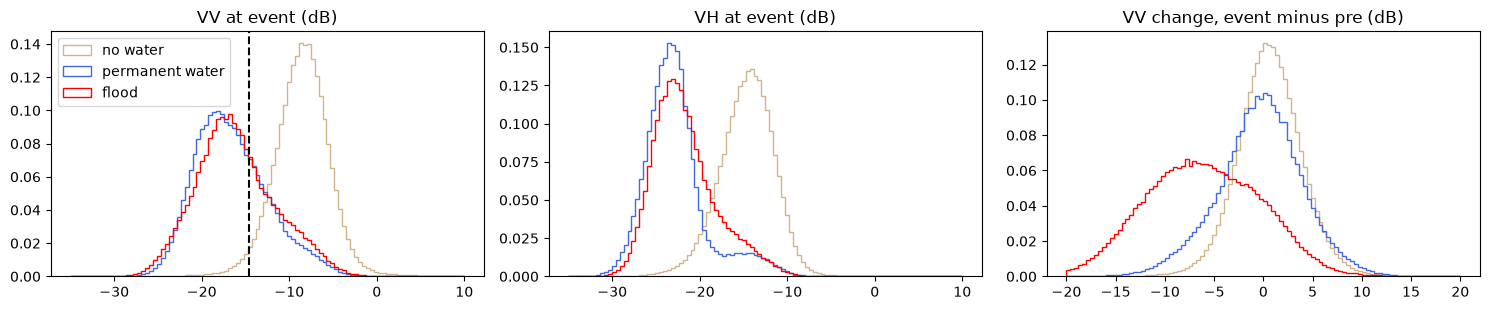

In [15]:
by_class = {c: {"vv": [], "vh": [], "dvv": []} for c in [0, 1, 2]}
for path in sorted(glob.glob(f"{SHARDS}/seg_train/shard-*.tar"))[:3]:
    for s in read_shard(path):
        s1, m = s["s1rtc"].astype(np.float32), s["mask"]
        for c in by_class:
            sel = m == c
            by_class[c]["vv"].append(s1[1, 0][sel][::8])
            by_class[c]["vh"].append(s1[1, 1][sel][::8])
            by_class[c]["dvv"].append((s1[1, 0] - s1[0, 0])[sel][::8])
by_class = {c: {k: np.concatenate(v) for k, v in d.items()} for c, d in by_class.items()}

fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
for c, color in [(0, "tan"), (1, "royalblue"), (2, "red")]:
    for i, k in enumerate(["vv", "vh", "dvv"]):
        x = by_class[c][k]
        ax[i].hist(x[np.isfinite(x)], bins=100, range=(-35, 10) if i < 2 else (-20, 20),
                   density=True, histtype="step", color=color, label=CLASSES[c])
ax[0].axvline(-14.6, ls="--", c="k")
ax[0].set_title("VV at event (dB)"); ax[1].set_title("VH at event (dB)")
ax[2].set_title("VV change, event minus pre (dB)"); ax[0].legend()
plt.tight_layout()

for c in [0, 2]:
    vv = by_class[c]["vv"]; vv = vv[np.isfinite(vv)]
    print(f"{CLASSES[c]:>10}: VV below -14.6 dB in {(vv < -14.6).mean() * 100:.1f}% of pixels")

At event time, flood and permanent water have almost the same VV and VH values; both are
much darker than dry land

## 9. Does seg_val look like seg_train?

seg_val (11 events) picks the checkpoint, so it should not be very different from training.

In [16]:
regions = pd.read_csv("../splits/patch_assignment.csv")[["patch_id", "region"]]
pr = patches.merge(regions, on="patch_id")

summary = pr.groupby("split")[["no_water", "permanent", "flood", "ignore"]].mean().round(3)
summary["patches with >1% flood"] = pr.groupby("split").flood.apply(lambda f: round((f > 0.01).mean(), 3))
display(summary)
pd.crosstab(pr.region, pr.split, normalize="columns").round(3)

,no_water,permanent,flood,ignore,patches with >1% flood
split,,,,,
seg_train,0.819,0.083,0.081,0.017,0.428
seg_val,0.848,0.045,0.082,0.026,0.393


split,seg_train,seg_val
region,,
Africa,0.140,0.299
C/S America,0.025,0.000
E/SE Asia,0.077,0.000
Europe,0.536,0.661
Middle East/C Asia,0.012,0.000
N America,0.129,0.000
Oceania,0.060,0.040
South Asia,0.021,0.000


The flood share appears to be same in both seg_train and seg_val (8%). Seg_val has less permanent. One of the African flood event first had 839 of seg_val's 1435 patches so the checkpoint choice would mostly have reflect that singular event. The seg_val is capped at 150 patches per flood: now 30% Africa and 66% Europe, and EMSR264 holds 22% of the flood pixels instead of about 60%. seg_val covers only 3 regions, against 8 in seg_train.

## 10. Nepal compared with the training data

Similar to holdout, Nepal is another test case we are going to consider. This section is just an exploration of the data from Nepal and is not used to choose settings. The inputs here are S1 radar on Aug 16 before the flood and 28 Aug after the flood and the Copernicus DEM. The radar is converted to dB like we did for training data. The referece is UNOSAT's flood outline drawn from optical images which does not separate the river from new flooding

In [ ]:
import rasterio
import geopandas as gpd
from rasterio.features import geometry_mask
from rasterio.warp import reproject, Resampling
from scipy import ndimage

NEPAL = "D:/data/nepal"

def load_db(path):
    with rasterio.open(path) as src:
        x = src.read().astype(np.float32)
        x[x == src.nodata] = np.nan
        return 10 * np.log10(x), src.transform, src.crs, src.shape

pre_np, transform, crs, shape = load_db(f"{NEPAL}/s1/s1rtc_20260816_orbit85_ascending.tif")
post_np, _, _, _ = load_db(f"{NEPAL}/s1/s1rtc_20260828_orbit85_ascending.tif")

flood_ref = gpd.read_file(f"{NEPAL}/unosat/extent/FloodExtent_20260826_Nepal.shp").to_crs(crs)
area = gpd.read_file(f"{NEPAL}/unosat/analysis/UNOSAT_Analysis_extent_20260826_20260827.shp").to_crs(crs)
in_flood = ~geometry_mask(flood_ref.geometry, shape, transform)
in_area = ~geometry_mask(area.geometry, shape, transform)

dem_np = np.zeros(shape, np.float32)
with rasterio.open(f"{NEPAL}/dem/copdem_glo30.tif") as src:
    reproject(rasterio.band(src, 1), dem_np, dst_transform=transform, dst_crs=crs,
              resampling=Resampling.bilinear)

print(f"{shape[0]} x {shape[1]} pixels of 10 m | analysis area {in_area.sum() / 1e4:.1f} km2, "
      f"reference flood {in_flood.sum() / 1e4:.1f} km2 ({in_flood.sum() / in_area.sum() * 100:.1f}%)")

6418 x 5692 pixels of 10 m | analysis area 363.0 km2, reference flood 37.4 km2 (10.3%)


### Radar values: Nepal against the training classes

,VV median (dB),VV < -14.6 dB (%),change < -3 dB (%),change > +3 dB (%)
Nepal: flood (reference),-7.7,10.5,19.7,19.9
Nepal: rest of analysis area,-7.4,4.5,11.7,12.2
training: no water,-8.5,3.1,12.3,21.8
training: permanent water,-17.0,70.3,24.8,20.4
training: flood,-16.5,66.6,69.3,5.7


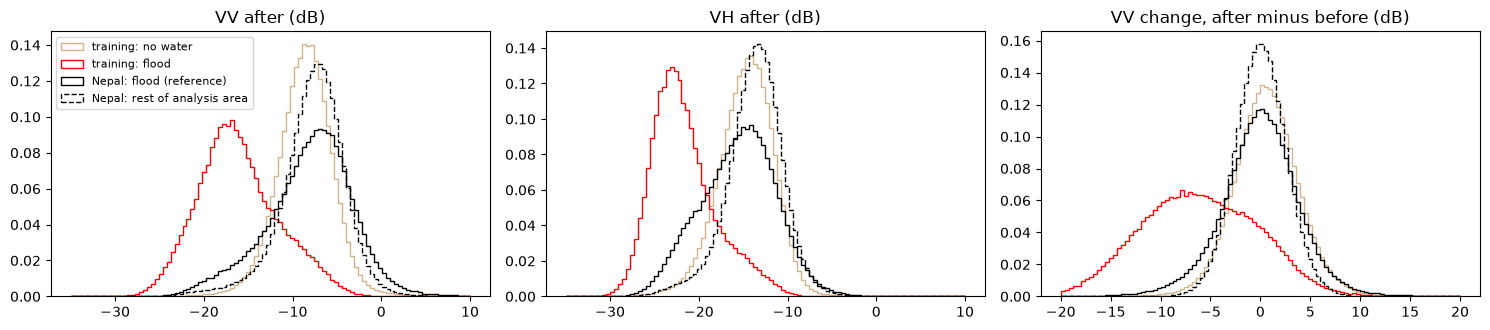

In [18]:
nepal = {"flood (reference)": in_flood, "rest of analysis area": in_area & ~in_flood}
nep_vals = {"vv": post_np[0], "vh": post_np[1], "dvv": post_np[0] - pre_np[0]}

fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
for i, (k, title) in enumerate([("vv", "VV after (dB)"), ("vh", "VH after (dB)"),
                                ("dvv", "VV change, after minus before (dB)")]):
    bins = (-35, 10) if i < 2 else (-20, 20)
    for c, color in [(0, "tan"), (2, "red")]:
        x = by_class[c][k]
        ax[i].hist(x[np.isfinite(x)], bins=100, range=bins, density=True, histtype="step",
                   color=color, label=f"training: {CLASSES[c]}")
    for (name, m), style in zip(nepal.items(), ["-", "--"]):
        x = nep_vals[k][m]
        ax[i].hist(x[np.isfinite(x)], bins=100, range=bins, density=True, histtype="step",
                   color="k", ls=style, label=f"Nepal: {name}")
    ax[i].set_title(title)
ax[0].legend(fontsize=8)
plt.tight_layout()

def radar_stats(vv, d):
    vv, d = vv[np.isfinite(vv)], d[np.isfinite(d)]
    return {"VV median (dB)": np.median(vv), "VV < -14.6 dB (%)": (vv < -14.6).mean() * 100,
            "change < -3 dB (%)": (d < -3).mean() * 100, "change > +3 dB (%)": (d > 3).mean() * 100}

rows = {f"Nepal: {name}": radar_stats(nep_vals["vv"][m], nep_vals["dvv"][m]) for name, m in nepal.items()}
rows.update({f"training: {CLASSES[c]}": radar_stats(by_class[c]["vv"], by_class[c]["dvv"]) for c in [0, 1, 2]})
pd.DataFrame(rows).T.round(1)

The 28 Aug radar looks like dry land, not like the training floods: VV median -7.7 dB (training flood -16.5, training no water -8.5), and only 10.5% of pixels are below the -14.6 dB baseline threshold (67% for training flood). Only 20% of pixels got more than 3 dB darker, against 69% for training flood. Two days after the event, most of the mapped area shows no open water in radar.

### Terrain

,elevation median (m),slope median (deg),slope > 15 deg (%),slope > 30 deg (%)
training: all pixels,62.0,2.9,8.4,1.8
training: flood pixels,NaN,0.0,0.6,0.1
Nepal: analysis area,1806.9,32.2,87.1,57.0
Nepal: reference flood,1649.3,22.7,63.0,37.1


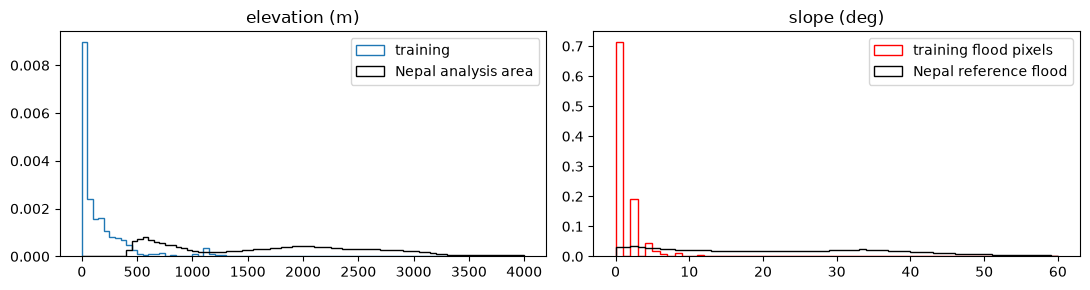

In [19]:
train_elev, train_slope, train_flood_slope = [], [], []
for path in sorted(glob.glob(f"{SHARDS}/seg_train/shard-*.tar"))[:3]:
    for s in read_shard(path):
        d = s["dem"][0].astype(np.float32)
        gy, gx = np.gradient(d, 10)
        slope = np.degrees(np.arctan(np.hypot(gx, gy)))
        train_elev.append(d[::8, ::8].ravel())
        train_slope.append(slope[::8, ::8].ravel())
        train_flood_slope.append(slope[s["mask"] == 2])
train_elev, train_slope = np.concatenate(train_elev), np.concatenate(train_slope)
train_flood_slope = np.concatenate(train_flood_slope)

gy, gx = np.gradient(dem_np, 10)
nep_slope = np.degrees(np.arctan(np.hypot(gx, gy)))

groups = {"training: all pixels": (train_elev, train_slope),
          "training: flood pixels": (None, train_flood_slope),
          "Nepal: analysis area": (dem_np[in_area], nep_slope[in_area]),
          "Nepal: reference flood": (dem_np[in_flood], nep_slope[in_flood])}
table = pd.DataFrame({name: {"elevation median (m)": np.median(e) if e is not None else np.nan,
                             "slope median (deg)": np.median(s),
                             "slope > 15 deg (%)": (s > 15).mean() * 100,
                             "slope > 30 deg (%)": (s > 30).mean() * 100}
                      for name, (e, s) in groups.items()}).T

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].hist(train_elev, bins=80, range=(0, 4000), density=True, histtype="step", label="training")
ax[0].hist(dem_np[in_area], bins=80, range=(0, 4000), density=True, histtype="step", color="k",
           label="Nepal analysis area")
ax[0].set_title("elevation (m)"); ax[0].legend()
for x, lbl, color in [(train_flood_slope, "training flood pixels", "red"),
                      (nep_slope[in_flood], "Nepal reference flood", "k")]:
    ax[1].hist(x, bins=60, range=(0, 60), density=True, histtype="step", color=color, label=lbl)
ax[1].set_title("slope (deg)"); ax[1].legend()
plt.tight_layout()
table.round(1)

The terrain is nothing like the training data. Training floods appear on flat ground with a median slope of 0 degrees, almost none are steeper than 15 degrees. Nepal on the other hand has around 63% of flood areas stepper than 15 degrees at about 1650 m. The two DEMs arent the same so comparison should be taken with a grain of salt.

### Shape of the flooded areas

For each flood pixel, the distance to the nearest dry pixel: small means thin strips and large means wide flooded plains.


In [20]:
train_dist = []
for path in sorted(glob.glob(f"{SHARDS}/seg_train/shard-*.tar"))[:3]:
    for s in read_shard(path, images=False):
        f = s["mask"] == 2
        if f.any():
            train_dist.append(ndimage.distance_transform_edt(f)[f] * 10)
train_dist = np.concatenate(train_dist)
nep_dist = ndimage.distance_transform_edt(in_flood)[in_flood] * 10

for name, d in [("training flood", train_dist), ("Nepal reference flood", nep_dist)]:
    print(f"{name:>22}: median {np.median(d):5.0f} m, 90th percentile {np.percentile(d, 90):5.0f} m, "
          f"within 20 m of the edge {(d <= 20).mean() * 100:4.1f}%")

        training flood: median    82 m, 90th percentile   561 m, within 20 m of the edge 17.4%
 Nepal reference flood: median    90 m, 90th percentile   398 m, within 20 m of the edge 11.3%


The flooded areas seem to be as wide as in training (median distance to the edge 90m vs 82m) so the difference is what the ground looks like inside the outline, not its shape.

### What a 256 x 256 Nepal patch looks like

The window with the most reference flood (same size as a training patch), shown like section 5
but without S2, since the Nepal model input is radar and DEM.

window rows 768-1024, cols 5120-5376; reference flood 64% of the window


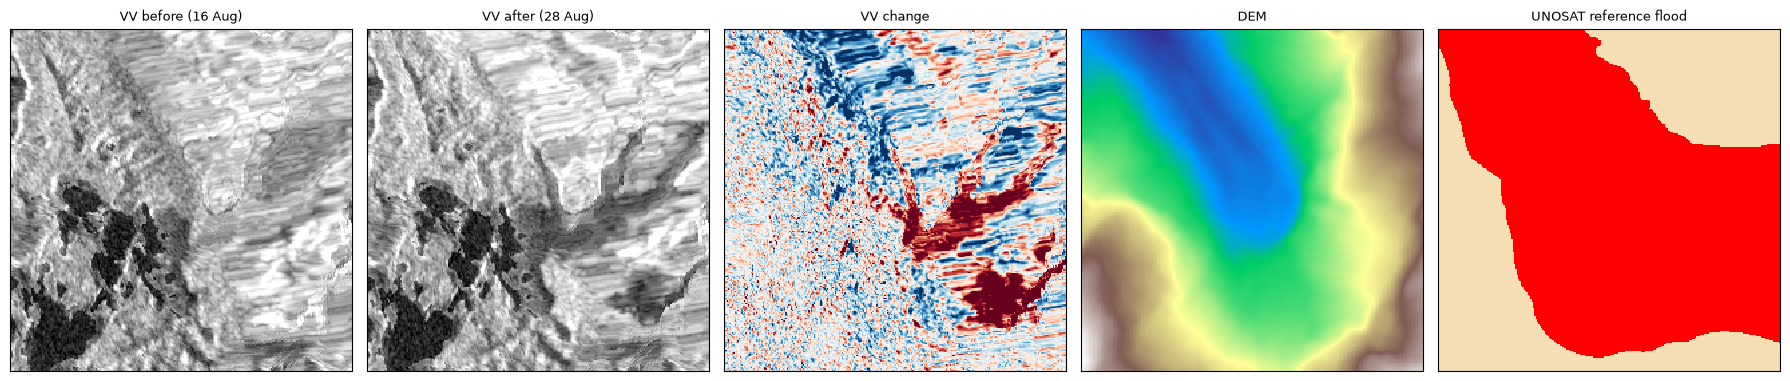

In [21]:
best, best_n = None, -1
for r in range(0, shape[0] - 256, 128):
    for c in range(0, shape[1] - 256, 128):
        n = in_flood[r:r + 256, c:c + 256].sum()
        if n > best_n:
            best, best_n = (r, c), n
r, c = best
win = (slice(r, r + 256), slice(c, c + 256))
panels = [(pre_np[0][win], "VV before (16 Aug)", "gray", (-25, 0)),
          (post_np[0][win], "VV after (28 Aug)", "gray", (-25, 0)),
          ((post_np[0] - pre_np[0])[win], "VV change", "RdBu", (-8, 8)),
          (dem_np[win], "DEM", "terrain", (None, None)),
          (in_flood[win], "UNOSAT reference flood", ListedColormap(["wheat", "red"]), (0, 1))]
fig, axes = plt.subplots(1, 5, figsize=(18, 3.8))
for ax, (img, title, cmap, (lo, hi)) in zip(axes, panels):
    ax.imshow(img, cmap=cmap, vmin=lo, vmax=hi, interpolation="nearest")
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
print(f"window rows {r}-{r + 256}, cols {c}-{c + 256}; reference flood {best_n / 256**2 * 100:.0f}% of the window")

This patch from the upper Bhote Koshi region which is where the radar changes. As seen some area get more than 8 dB darker, possibly the new flood water or wet debris as a result of the flood water. The reference marks the whole damaged valley floor, the radar sees the visible water parts of it. 

## Summary

- Dates, masks and images are consistent; nothing to fix in the data.
- IBM's class weights and normalisation stats are close enough to ours to keep.
- About half of event-time S2 images are mostly cloud, which argues for training a radar + DEM model first.
- Radar separates flood from permanent water through the change from pre-event, so both time steps are needed.
- Flood is concentrated in a few events and many patches have none, so results are reported per event,
  and flood fraction is a control for the error spotter.
- One event dominated seg_val, so seg_val is capped at 150 patches per event.
- Nepal is very different from the training data: steep terrain, and two days after the
  event most of the mapped area shows no open-water signal in radar